# WakeWise NL: wake-aware wind-turbine siting for Newfoundland's west coast with QAOA

**Team AI Entanglers** (Mostafa Wasib and Mahmoud Al-Moghrabi) · Qiskit Fall Fest 2026, Memorial University · Theme: *Quantum for a Sustainable Newfoundland and Labrador*

**Question.** On a wind parcel at Wreckhouse, beside the Codroy Valley where a large wind-to-hydrogen project is proposed, which candidate sites should get a turbine so the farm delivers the most net clean energy once each turbine's wake (the slower air behind its rotor) is accounted for, and does that choice hold up from one year's wind to the next?

**Approach.** Wind-farm physics from **DTU PyWake** (an industry-standard open-source wind-farm simulator) driven by **three years of real hourly wind** (2023 to 2025) from Environment and Climate Change Canada. Every wake loss involves a *pair* of turbines, so the siting problem is a quadratic binary optimization (QUBO) that maps one-to-one onto an Ising Hamiltonian: each site is a qubit, each turbine's value is a $Z$ field, each wake interaction is a $ZZ$ coupling. We solve it with **QAOA in Qiskit** and compare against exact enumeration, a greedy planner and random guessing on the same instances, in noiseless simulation, under an IBM noise model, and on real hardware: **IBM Quantum System One in Quebec** (`ibm_quebec`, 156 qubits), with repeated runs.

**Results at a glance** (details and sources in Sections 2 to 9):

* **Real data:** 26,264 hours of 2023 to 2025 Wreckhouse wind. One 4 MW turbine alone would yield about 17,600 MWh/yr (50% capacity factor) and run at full power 32% of the time.
* **Industry-standard physics:** DTU PyWake. A badly placed neighbour costs a turbine up to 2.4% of its output; a dense 12-turbine block loses 4.2% to wakes.
* **Recommended decision:** the best layout for the 3-year wind climate builds 9 turbines (about 154 GWh/yr, the electricity of roughly 9,100 NL homes). It is also the best possible layout for 2023 and 2024 and gives up just 1 MWh/yr in 2025, while a layout designed on 2025 alone would give up 357 to 416 MWh/yr in the calmer years.
* **Classical baseline:** greedy finds the 3-year optimum, but falls 2% to 8% short on single years (up to 704 MWh/yr in 2023).
* **Quantum, noiseless (12 qubits):** QAOA at depth 3 with CVaR training returns the optimal layout in 8.4% of shots, about 345 times more often than random guessing (34 shots for 95% confidence, versus 12,269). On single years it hits each year's optimum in 9% to 12% of shots, and up to 59% of its samples beat greedy.
* **Real hardware, IBM Quantum System One in Quebec** (`ibm_quebec`, 8 jobs, 56 s of QPU time): on the 3-year climate, across 3 independent runs, the optimal layout appears about 22 times more often than random guessing (0.47% to 0.60% of shots). On 2023's wind, 15% to 17% of hardware samples beat the greedy planner, against 2% for the random control circuit. At 16 qubits the samples stay clearly better than random (gap closed 0.32 to 0.42) but the optimum itself was not sampled: today's limit for this method.
* **Model check:** the pairwise QUBO ranks layouts like full PyWake simulations (rank correlation 0.99 with both the Jensen and a Gaussian wake model), and its optimum is the best layout under both.
* **Honest scope:** no quantum advantage is claimed. At 12 to 16 sites a laptop solves the problem exactly, which is precisely what lets us measure QAOA's quality.

## 0. Reproducibility (read first)

| Item | Details |
|---|---|
| Environment | Python 3.12 virtual environment; exact package versions are printed in the next cell and pinned in `requirements.txt`. Developed on macOS (Apple silicon). |
| Setup and run | `git clone https://github.com/mrw-soumik/Qiskit-AI-Entanglers-.git && cd Qiskit-AI-Entanglers-`<br>`python3.12 -m venv .venv && source .venv/bin/activate && pip install -r requirements.txt`<br>`python test_wakewise.py` (self-checks)<br>`jupyter nbconvert --to notebook --execute --inplace wakewise.ipynb` (about 15 minutes on a laptop, **no IBM account needed**) |
| Input data | `data/wreckhouse_{2023,2024,2025}_hourly.csv`: Environment and Climate Change Canada hourly wind at Wreckhouse, NL (climate ID 8404343), Open Government Licence (Canada). Format: CSV with `LOCAL_DATE` (local time), `WIND_DIRECTION` (tens of degrees the wind blows from; 0 = calm) and `WIND_SPEED` (km/h at 10 m). Source URLs and retrieval times in `data/SOURCE.md`; regenerate with `wakewise.fetch_wind(year=...)`. Preparation: drop hours with a missing value; km/h to m/s; extrapolate 10 m to the 110 m hub with a power-law shear profile ($\alpha = 0.14$). The **long-term wind climate** pools all three years, every hour weighted equally (standard wind-resource practice); single years are used as robustness checks. |
| Wind-farm model | DTU PyWake 2.6: generic 4 MW turbine (130 m rotor, 110 m hub, physics-based power and thrust curves); Jensen/Park wake model (`NOJ`, $k = 0.075$) to build the QUBO; full-farm Jensen and Bastankhah-Porte-Agel Gaussian models to check it (Section 7). |
| Instances | `climate_12`: 3 x 4 grid (12 qubits) on the 3-year climate (main); `climate_16`: 4 x 4 grid (16 qubits, scale test); `y2023_12`, `y2024_12`, `y2025_12`: the 12-site grid on single years (robustness). All defined in `wakewise.INSTANCES`. |
| Seeds and settings | COBYLA (SciPy), `maxiter=300`, 5 starting points drawn with NumPy seed 7. QAOA angles are trained on exact statevectors with the CVaR objective ($\alpha = 0.25$); the standard energy objective is reported for comparison. Ideal sampling: `StatevectorSampler(seed=11)`, 10,000 shots. Noise model: `FakeFez` (IBM Heron r2, the generation of today's `ibm_quebec`), `seed_simulator=42`, 4,000 shots. Transpiler: preset pass manager, `optimization_level=3`, `seed_transpiler=1`. |
| Baseline and evaluation | Section 3: exact optimum (all $2^n$ layouts), greedy planner, uniform-random control. Every sampled layout, quantum or classical, is scored with the same full QUBO via `wakewise.summarize`. |
| Hardware | `RUN_HARDWARE` is off by default; the notebook loads `results/hardware_<instance>_r<k>.json` (device, job ID, shots, error-suppression options, calibration snapshot, QPU seconds, transpiled two-qubit gate counts, raw counts). To rerun: copy `.env.example` to `.env` (or create `api.json`), add your `apikey` and `crn`, then `python wakewise.py hardware climate_12 3`. |
| Simulator vs hardware | Sections 5, 7 and 8 are noiseless simulation. Section 6 reports noiseless simulation, the noise-model simulation and real `ibm_quebec` hardware in separate, labelled columns. |

**What is real and what is assumed**

| Input | Status |
|---|---|
| Hourly wind direction and speed, Wreckhouse 2023 to 2025 | **Observed** (ECCC) |
| Hub-height extrapolation ($\alpha = 0.14$) | Assumption (standard open-terrain value) |
| Turbine: 4 MW, 130 m rotor, 110 m hub | Illustrative class, with power and thrust curves from PyWake's physics-based generic turbine model |
| Wake physics | PyWake Jensen/Park model (industry standard); pairwise approximation checked against full-farm Jensen and Gaussian models |
| Parcel: flat grid, 650 m (5 rotor diameters) apart | Illustrative |
| Costs expressed as energy: 88% of a turbine's free-stream output + 2% per 650 m of cable | Illustrative (sensitivity tested in Section 3) |

In [1]:
import os, sys, json, glob, platform, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import qiskit, qiskit_aer, qiskit_ibm_runtime, scipy, py_wake
import wakewise as ww

warnings.filterwarnings("ignore")  # library deprecation notices and local-simulator option notices
print(f"Python {sys.version.split()[0]} | {platform.system()} {platform.machine()}")
print(f"qiskit {qiskit.__version__} | qiskit-aer {qiskit_aer.__version__} | qiskit-ibm-runtime {qiskit_ibm_runtime.__version__} "
      f"| py_wake {py_wake.__version__} | numpy {np.__version__} | scipy {scipy.__version__} | pandas {pd.__version__}")

RUN_HARDWARE = os.environ.get("RUN_HARDWARE") == "1"     # default: load saved hardware results
SEED_STARTS, SEED_SAMPLER, SEED_NOISE = 7, 11, 42
SHOTS_IDEAL, SHOTS_DEVICE, ALPHA = 10_000, 4_000, 0.25
HOME_MWH = 17.0   # NL household electricity use, about 1,400-1,500 kWh/month (NL Government, 2026)
FIG = ww.ROOT / "figures"; FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 220, "axes.spines.top": False, "axes.spines.right": False})

Python 3.12.4 | Darwin arm64
qiskit 2.6.2 | qiskit-aer 0.18.2 | qiskit-ibm-runtime 0.51.0 | py_wake 2.6.20 | numpy 2.5.4 | scipy 1.18.1 | pandas 3.1.1


## 1. The problem, why it matters in Newfoundland and Labrador, and the sustainability benefit

**Local relevance.** Wreckhouse, on the island's southwest coast between Cape Ray and St. Andrew's, is famous for south-easterly gales strong enough to have blown railway cars off the tracks ([Wreckhouse](https://en.wikipedia.org/wiki/Wreckhouse,_Newfoundland_and_Labrador)). The neighbouring Codroy Valley and the Port au Port Peninsula are where World Energy GH2's *Project Nujio'qonik* proposes wind farms (at least 150 turbines) to power a hydrogen and ammonia plant in Stephenville; the province released it from environmental assessment, with conditions, in April 2024 ([NL Government bulletin](https://www.gov.nl.ca/releases/2024/ecc-en/0409n05/), [CBC](https://www.cbc.ca/news/canada/newfoundland-labrador/wegh2-environment-approval-1.7168450)). MUN's NSERC CREATE-SWIFT program, presented at this Fall Fest, explicitly calls for wind-energy optimization benchmarks that compare classical and quantum or hybrid methods.

**Decision.** Which of $n$ candidate sites on a parcel get a turbine ($x_i = 1$) or not ($x_i = 0$).

**Intended use of the output.** Early-stage layout screening: the best layouts, the energy at stake, and whether the choice is robust to year-to-year wind. Not a construction recommendation.

**Sustainability benefit.** Turbines placed in each other's wakes waste wind. Layouts that lose less energy deliver more clean electricity (or green hydrogen) from the same land, steel and concrete, or the same energy from fewer turbines and less disturbed ground. The prototype demonstrates the *decision method* on a small idealized parcel; the real-world benefit would come from applying it with site-specific terrain, turbines and costs.

**Objective (QUBO, energy units of MWh per year, lower is better)**

$$f(x) = -\sum_i (E - c_i)\,x_i \;+\; \sum_{i<j} W_{ij}\,x_i x_j$$

* $E$: annual energy of one turbine standing alone, simulated hour by hour from the real wind.
* $c_i$: annualized cost of a turbine at site $i$, expressed as energy (base cost plus cable to the substation at site 0).
* $W_{ij}$: annual energy the pair $i, j$ loses to each other's wakes, simulated with PyWake on that pair alone.

Every bitstring is a valid layout, so there are no penalty terms to tune. This is the classic grid-based wind-farm layout setting (Mosetti et al., 1994) in a QUBO-friendly linear form.

## 2. Data: three years of hourly wind at Wreckhouse

,usable hours,mean hub speed (m/s),one turbine alone (MWh/yr),hours at 95%+ of rated power
year,,,,
2023,8750,9.14,17961,32%
2024,8774,8.60,16270,28%
2025,8740,9.38,18498,35%
2023-2025 climate,26264,9.04,17575,32%


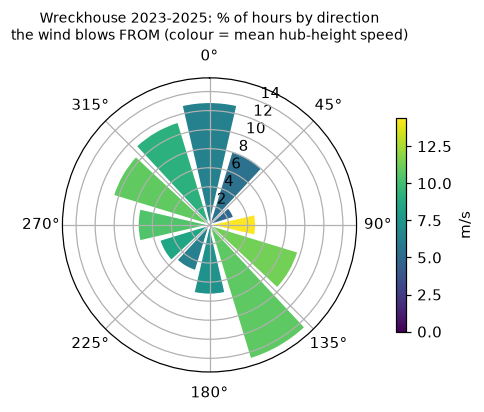

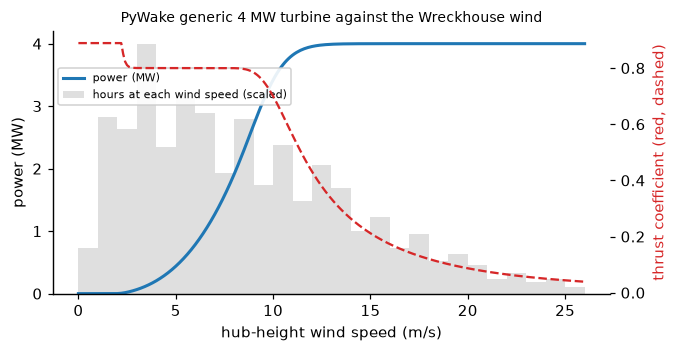

In [2]:
wd, u = ww.load_wind()            # 3-year climate, 2023-2025
wt = ww.turbine()
p_kw = wt.power(u) / 1e3
jensen, gaussian = ww.wake_model("jensen"), ww.wake_model("gaussian")
rows = []
for y in ww.YEARS:
    wd_y, u_y = ww.load_wind((y,))
    E_y = ww.farm_energy(jensen, np.zeros((1, 2)), wd_y, u_y)[0]
    rows.append({"year": y, "usable hours": len(u_y), "mean hub speed (m/s)": round(u_y.mean(), 2),
                 "one turbine alone (MWh/yr)": round(E_y), "hours at 95%+ of rated power": f"{(wt.power(u_y) / 1e3 >= 0.95 * ww.RATED_KW).mean():.0%}"})
rows.append({"year": "2023-2025 climate", "usable hours": len(u), "mean hub speed (m/s)": round(u.mean(), 2),
             "one turbine alone (MWh/yr)": round(ww.farm_energy(jensen, np.zeros((1, 2)), wd, u)[0]),
             "hours at 95%+ of rated power": f"{(p_kw >= 0.95 * ww.RATED_KW).mean():.0%}"})
wind_table = pd.DataFrame(rows).set_index("year")
display(wind_table)

sector = ((wd + 15) % 360 // 30).astype(int)
freq = np.bincount(sector, minlength=12) / len(sector)
mean_speed = np.array([u[sector == s].mean() for s in range(12)])
fig = plt.figure(figsize=(4.6, 4.2))
ax = fig.add_subplot(projection="polar")
ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
ax.bar(np.radians(np.arange(12) * 30), freq * 100, width=np.radians(26),
       color=plt.cm.viridis(mean_speed / mean_speed.max()), edgecolor="white")
ax.set_title("Wreckhouse 2023-2025: % of hours by direction\nthe wind blows FROM (colour = mean hub-height speed)", fontsize=9)
sm = plt.cm.ScalarMappable(cmap="viridis", norm=plt.Normalize(0, mean_speed.max()))
fig.colorbar(sm, ax=ax, shrink=0.6, pad=0.1, label="m/s")
fig.savefig(FIG / "wind_rose.png", bbox_inches="tight"); plt.show()

fig, ax2 = plt.subplots(figsize=(6.4, 3.3))
hist, edges = np.histogram(u, bins=26, range=(0, 26))
ax2.bar(edges[:-1], hist / hist.max() * ww.RATED_KW / 1000, width=1.0, align="edge", color="gray", alpha=0.25,
        label="hours at each wind speed (scaled)")
ws = np.linspace(0, 26, 261)
ax2.plot(ws, wt.power(ws) / 1e6, color="tab:blue", lw=2, label="power (MW)")
ax2.set_xlabel("hub-height wind speed (m/s)"); ax2.set_ylabel("power (MW)")
ax3 = ax2.twinx(); ax3.plot(ws, wt.ct(ws), color="tab:red", lw=1.5, ls="--")
ax3.set_ylabel("thrust coefficient (red, dashed)", color="tab:red"); ax3.spines["top"].set_visible(False)
ax2.legend(fontsize=7, loc="upper left", bbox_to_anchor=(0.0, 0.88), framealpha=0.9)
ax2.set_title("PyWake generic 4 MW turbine against the Wreckhouse wind", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "turbine.png", bbox_inches="tight"); plt.show()

The wind is strongly bimodal: south-easterlies (the Wreckhouse gales) and north-westerlies dominate, so turbines lined up on that axis shade each other most. It is also strong enough that turbines often run at full power, when a wake costs almost nothing; this is why wake losses here are milder than at an average site. Calmer years (2024) make wakes matter more.

## 3. Classical model and baselines

The main instance is a 3 x 4 grid of candidate sites, 650 m (5 rotor diameters) apart, on the 3-year wind climate (`climate_12`, 12 qubits). We also build the same grid on each single year, and a 4 x 4 grid (`climate_16`, 16 qubits) as a scale test.

In [3]:
inst = {k: ww.instance(k, model=jensen) for k in ["climate_12", "climate_16", "y2023_12", "y2024_12", "y2025_12"]}
d = inst["climate_12"]
E = d["E"]
iu = np.triu_indices(12, 1)
Wm = d["W"][iu]
block_loss = 1 - ww.farm_energy(jensen, d["xy"], d["wd"], d["u"]).sum() / (12 * E)
print(f"3-year climate: one turbine alone E = {E:,.0f} MWh/yr (capacity factor {E / (ww.RATED_KW / 1000 * 8760):.0%})")
print(f"wake couplings (12 sites): largest {Wm.max():,.0f} MWh/yr ({Wm.max() / E:.1%} of E), median {np.median(Wm):,.0f}; "
      f"a full 12-turbine block loses {block_loss:.1%} to wakes")

bits = lambda x: "".join(str(int(b)) for b in x)
rows = []
for k, dd in inst.items():
    rows.append({"instance": k, "qubits": len(dd["lin"]), "layouts": 2 ** len(dd["lin"]), "turbines in optimum": int(dd["x_opt"].sum()),
                 "optimal layout (site 0 first)": bits(dd["x_opt"]), "greedy shortfall (MWh/yr)": round(dd["f_gr"] - dd["f_opt"]),
                 "greedy gap (% of net value)": f"{(dd['f_gr'] - dd['f_opt']) / abs(dd['f_opt']):.1%}"})
baseline_table = pd.DataFrame(rows).set_index("instance")
baseline_table

3-year climate: one turbine alone E = 17,575 MWh/yr (capacity factor 50%)
wake couplings (12 sites): largest 425 MWh/yr (2.4% of E), median 95; a full 12-turbine block loses 4.2% to wakes


,qubits,layouts,turbines in optimum,optimal layout (site 0 first),greedy shortfall (MWh/yr),greedy gap (% of net value)
instance,,,,,,
climate_12,12,4096,9,111110001111,0,0.0%
climate_16,16,65536,9,1111100011110000,0,0.0%
y2023_12,12,4096,9,111110001111,704,8.2%
y2024_12,12,4096,9,111110001111,409,5.5%
y2025_12,12,4096,10,111111001111,195,2.0%


**Reading the table.** On the long-term climate the greedy planner happens to find the optimum. On every single year it does not: it falls short by 2% to 8% of net value, because in a given year the wake interactions are stronger or differently shaped and greedy locks in early choices it cannot revisit. Section 8 shows that the long-term optimum is also the robust choice across years.

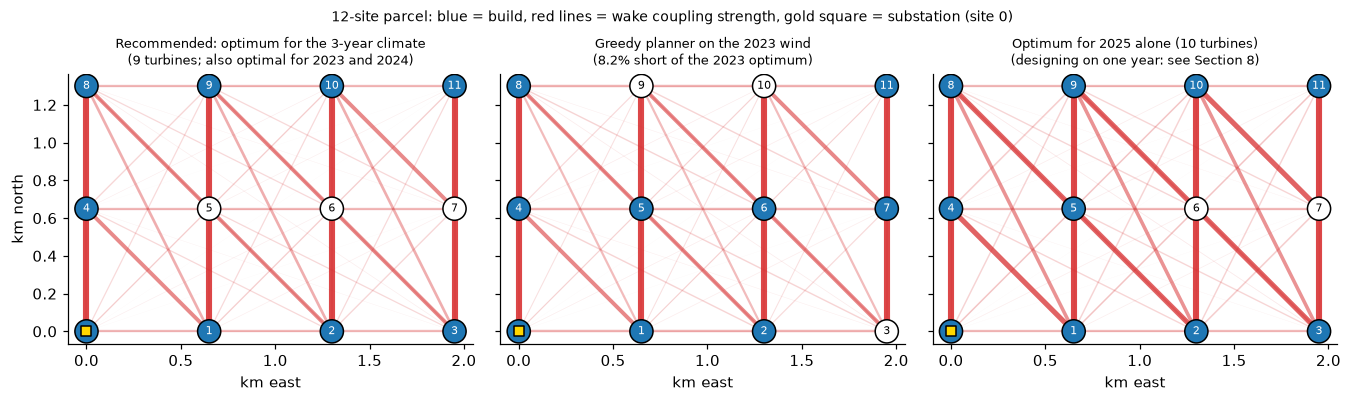

In [4]:
def draw_layout(ax, dd, x, title):
    xy = dd["xy"] / 1000
    W = dd["W"]
    for i, j in zip(*np.triu_indices(len(xy), 1)):
        if W[i, j] > 0:
            ax.plot(*xy[[i, j]].T, color="tab:red", alpha=0.85 * W[i, j] / W.max(), lw=4 * W[i, j] / W.max(), zorder=1)
    ax.scatter(*xy.T, s=230, c=["tab:blue" if b else "white" for b in x], edgecolors="black", zorder=2)
    for k, (px, py) in enumerate(xy):
        ax.annotate(str(k), (px, py), ha="center", va="center", fontsize=7, color="white" if x[k] else "black", zorder=3)
    ax.scatter(*xy[0], marker="s", s=36, c="gold", edgecolors="black", zorder=4)
    ax.set_title(title, fontsize=8.5); ax.set_aspect("equal"); ax.set_xlabel("km east")

y23, y25 = inst["y2023_12"], inst["y2025_12"]
fig, axs = plt.subplots(1, 3, figsize=(12.5, 3.5), sharey=True)
draw_layout(axs[0], d, d["x_opt"], f"Recommended: optimum for the 3-year climate\n({int(d['x_opt'].sum())} turbines; also optimal for 2023 and 2024)")
draw_layout(axs[1], y23, y23["x_gr"], f"Greedy planner on the 2023 wind\n({(y23['f_gr'] - y23['f_opt']) / abs(y23['f_opt']):.1%} short of the 2023 optimum)")
draw_layout(axs[2], y25, y25["x_opt"], f"Optimum for 2025 alone ({int(y25['x_opt'].sum())} turbines)\n(designing on one year: see Section 8)")
axs[0].set_ylabel("km north")
fig.suptitle("12-site parcel: blue = build, red lines = wake coupling strength, gold square = substation (site 0)", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "layouts.png", bbox_inches="tight"); plt.show()

**Sensitivity to the illustrative cost assumption** (3-year climate, 12 sites). The cost level decides how many turbines are worth building.

In [5]:
sens = []
for frac in [0.85, 0.88, 0.90, 0.92]:
    dd = ww.instance("climate_12", model=jensen, cost_frac=frac)
    sens.append({"base cost (fraction of E)": frac, "turbines in optimum": int(dd["x_opt"].sum()), "f*": round(dd["f_opt"]),
                 "greedy shortfall (MWh/yr)": round(dd["f_gr"] - dd["f_opt"]), "greedy gap": f"{(dd['f_gr'] - dd['f_opt']) / abs(dd['f_opt']):.1%}"})
pd.DataFrame(sens).set_index("base cost (fraction of E)")

,turbines in optimum,f*,greedy shortfall (MWh/yr),greedy gap
base cost (fraction of E),,,,
0.85,11,-13660,0,0.0%
0.88,9,-8583,0,0.0%
0.90,7,-5485,58,1.1%
0.92,6,-3242,6,0.2%


## 4. Quantum formulation: from wakes to an Ising Hamiltonian

Substituting $x_i = (1 - z_i)/2$, where $z_i = \pm 1$ is the eigenvalue of Pauli $Z$ on qubit $i$ (so $|0\rangle$ means "no turbine" and $|1\rangle$ means "turbine"), turns the QUBO into

$$H = \sum_i h_i Z_i + \sum_{i<j} J_{ij} Z_i Z_j,\qquad h_i = -\tfrac{1}{2}\ell_i - \tfrac{1}{4}\sum_{j} W_{ij},\qquad J_{ij} = \tfrac{1}{4}W_{ij},$$

with $f(x) = \langle x|H|x\rangle + \text{offset}$. The wake physics *is* the $ZZ$ coupling. `test_wakewise.py` checks this identity for every bitstring and confirms Qiskit's bit order (bit $i$ of a measured integer is site $i$).

**Role of the quantum component.** QAOA prepares $|\gamma,\beta\rangle = \prod_{k=1}^{p} e^{-i\beta_k \sum X}\, e^{-i\gamma_k H} |+\rangle^{\otimes n}$: cost layers apply the wake Hamiltonian as phases, mixer layers move amplitude between layouts, and interference concentrates probability on low-energy layouts. A classical optimizer (COBYLA) tunes $(\gamma, \beta)$; the circuit is then sampled and every sampled layout is scored with the full QUBO. **Input** to the quantum component: the Ising Hamiltonian $H$ (one $Z$ coefficient per site and one $ZZ$ coefficient per wake-interacting pair, built classically from the wind data) and the trained angles. **Output**: measured bitstrings, i.e. candidate layouts and how often each appears, which the classical post-processing scores. We follow the Qiskit pattern: map (QUBO to `SparsePauliOp` and `qaoa_ansatz`), optimize (transpile for the device), execute (Sampler), post-process (score and compare).

**Training objective (CVaR).** A planner needs the *best* layout, not a good average. Instead of minimizing the average energy $\langle H\rangle$, we minimize the average of the best 25% of outcomes (conditional value at risk, CVaR; Barkoutsos et al., *Quantum* 2020), which pushes probability onto the best layouts. Standard training is reported for comparison.

**Why this is an appropriate choice.** The problem is natively quadratic and binary, so there is no encoding overhead and no penalty term; it is NP-hard in general (it contains maximum-weight independent set as a special case); and at 12 to 16 qubits the exact answer is known, so QAOA's quality is measured rather than assumed.

**Metrics.** $P(\text{opt})$: probability that a shot returns an optimal layout. *Gap closed* $= (f_\text{random} - \langle f\rangle_\text{samples}) / (f_\text{random} - f^*)$: 0 means no better than uniform random guessing, 1 means always optimal. $N_{95}$: shots needed to see the optimum at least once with 95% probability, $\ln 0.05 / \ln(1 - P(\text{opt}))$. *Beats greedy*: share of samples better than the greedy planner's layout.

Hamiltonian on 12 qubits: 12 Z terms, 66 ZZ terms; |coefficient| max 789.6, offset -5,952.8 MWh/yr
check passed: <x|H|x> + offset equals the QUBO value for all 4,096 layouts
12-qubit p=1 circuit, gate counts after one decomposition: {'cx': 132, 'rz': 66, 'u': 12, 'p': 12, 'r': 12}


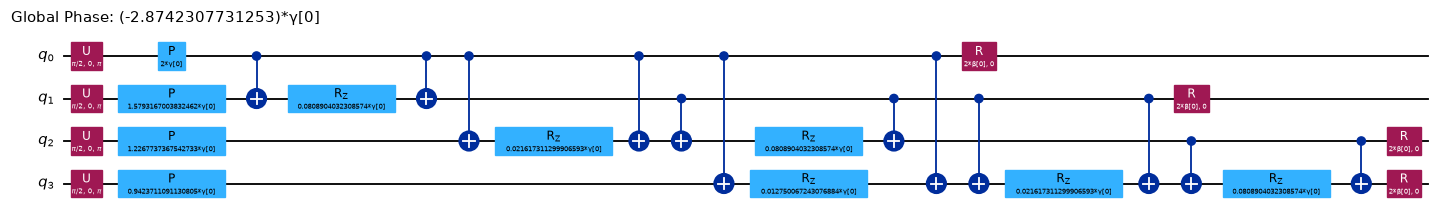

In [6]:
H, offset = ww.qubo_to_ising(d["lin"], d["W"])
scale = np.abs(H.coeffs).max()
Hn = H / scale                      # normalized for training; same minimizer
print(f"Hamiltonian on {H.num_qubits} qubits: {sum(1 for p in H.paulis if str(p).count('Z') == 1)} Z terms, "
      f"{sum(1 for p in H.paulis if str(p).count('Z') == 2)} ZZ terms; |coefficient| max {scale:,.1f}, offset {offset:,.1f} MWh/yr")
diag = H.to_matrix(sparse=True).diagonal().real + offset
assert np.allclose(diag, d["values"]), "Ising energies must equal QUBO values"
print("check passed: <x|H|x> + offset equals the QUBO value for all 4,096 layouts")
print("12-qubit p=1 circuit, gate counts after one decomposition:", dict(ww.qaoa_circuit(Hn, 1).decompose().count_ops()))
H4, _ = ww.qubo_to_ising(d["lin"][:4], d["W"][:4, :4])   # 4-site slice, only to show the circuit structure
ww.qaoa_circuit(H4 / np.abs(H4.coeffs).max(), 1).decompose().draw("mpl", fold=-1, scale=0.6)

## 5. QAOA on the main instance (12 qubits, noiseless simulation)

The $p=1$ energy landscape over $(\gamma, \beta)$ (exact, `StatevectorEstimator`), then circuits of depth $p = 1, 2, 3$ trained with CVaR and with the standard objective, each sampled 10,000 times.

trained p=1 angles (standard objective): gamma = 0.868, beta = 2.551


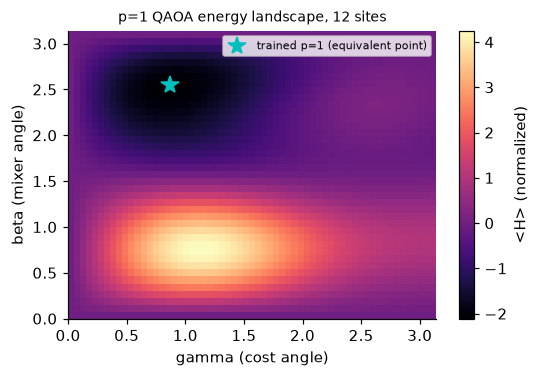

,P(opt),x random,P(opt) within 100 shots,gap closed,N95 shots
method,,,,,
uniform random (control),0.02%,1x,2%,0.00,"12,269"
QAOA p=1 (CVaR training),0.77%,32x,54%,0.60,388
QAOA p=2 (CVaR training),5.37%,220x,100%,0.70,54
QAOA p=3 (CVaR training),8.42%,345x,100%,0.76,34
QAOA p=1 (standard training),0.74%,30x,52%,0.64,403
QAOA p=2 (standard training),4.29%,176x,99%,0.73,68
QAOA p=3 (standard training),6.82%,279x,100%,0.79,42
greedy planner (one deterministic answer),100.00%,,,1.00,


In [7]:
from qiskit.primitives import StatevectorEstimator
ans1 = ww.qaoa_circuit(Hn, 1)                       # parameters ordered [beta, gamma]
gammas, betas = np.linspace(0, np.pi, 61), np.linspace(0, np.pi, 41)   # e^{-i beta sum X} has period pi in beta
grid_params = np.array([[b, g] for b in betas for g in gammas])
landscape = StatevectorEstimator().run([(ans1, Hn, grid_params)]).result()[0].data.evs.reshape(len(betas), len(gammas))

qaoa, standard = {}, {}
for p in [1, 2, 3]:
    ans = ww.qaoa_circuit(Hn, p)
    best, _ = ww.train_qaoa(ans, Hn, starts=5, seed=SEED_STARTS, values=d["values"], alpha=ALPHA)
    counts = ww.ideal_counts(ans, best.x, shots=SHOTS_IDEAL, seed=SEED_SAMPLER)
    qaoa[p] = dict(params=best.x, counts=counts, **ww.summarize(counts, d["lin"], d["W"], d["f_opt"], d["f_rand"]))
    best_e, _ = ww.train_qaoa(ans, Hn, starts=5, seed=SEED_STARTS)
    counts_e = ww.ideal_counts(ans, best_e.x, shots=SHOTS_IDEAL, seed=SEED_SAMPLER)
    standard[p] = dict(params=best_e.x, **ww.summarize(counts_e, d["lin"], d["W"], d["f_opt"], d["f_rand"]))

fig, ax = plt.subplots(figsize=(5.4, 3.4))
im = ax.imshow(landscape, origin="lower", aspect="auto", extent=[0, np.pi, 0, np.pi], cmap="magma")
b1, g1 = standard[1]["params"]
print(f"trained p=1 angles (standard objective): gamma = {g1:.3f}, beta = {b1:.3f}")
if g1 < 0:                      # H is real, so (gamma, beta) and (-gamma, -beta) give the same energy
    g1, b1 = -g1, -b1
if 0 <= g1 <= np.pi:
    ax.plot(g1, b1 % np.pi, "c*", ms=12, label="trained p=1 (equivalent point)")
    ax.legend(fontsize=7, loc="upper right")
ax.set_xlabel("gamma (cost angle)"); ax.set_ylabel("beta (mixer angle)")
fig.colorbar(im, label="<H> (normalized)"); ax.set_title("p=1 QAOA energy landscape, 12 sites", fontsize=9)
fig.savefig(FIG / "landscape.png", bbox_inches="tight"); plt.show()

p_rand = d["p_rand"]
n95 = lambda q: np.log(0.05) / np.log1p(-q) if q > 0 else np.inf
def beats_greedy(counts, dd=d):
    states = np.array([int(s) for s in counts]); w = np.array(list(counts.values()), float)
    return float(w[dd["values"][states] < dd["f_gr"] - 1e-9].sum() / w.sum())

rows = [{"method": "uniform random (control)", "P(opt)": p_rand, "x random": 1.0, "P(opt) within 100 shots": 1 - (1 - p_rand) ** 100,
         "gap closed": 0.0, "N95 shots": n95(p_rand)}]
for p, r in qaoa.items():
    rows.append({"method": f"QAOA p={p} (CVaR training)", "P(opt)": r["p_opt"], "x random": r["p_opt"] / p_rand,
                 "P(opt) within 100 shots": 1 - (1 - r["p_opt"]) ** 100, "gap closed": r["gap_closed"], "N95 shots": n95(r["p_opt"])})
for p, r in standard.items():
    rows.append({"method": f"QAOA p={p} (standard training)", "P(opt)": r["p_opt"], "x random": r["p_opt"] / p_rand,
                 "P(opt) within 100 shots": 1 - (1 - r["p_opt"]) ** 100, "gap closed": r["gap_closed"], "N95 shots": n95(r["p_opt"])})
rows.append({"method": "greedy planner (one deterministic answer)", "P(opt)": float(np.isclose(d["f_gr"], d["f_opt"])), "x random": np.nan,
             "P(opt) within 100 shots": np.nan, "gap closed": (d["f_rand"] - d["f_gr"]) / (d["f_rand"] - d["f_opt"]), "N95 shots": np.nan})
ideal_table = pd.DataFrame(rows).set_index("method")
ideal_table.style.format({"P(opt)": "{:.2%}", "x random": "{:,.0f}x", "P(opt) within 100 shots": "{:.0%}",
                          "gap closed": "{:.2f}", "N95 shots": "{:,.0f}"}, na_rep="")

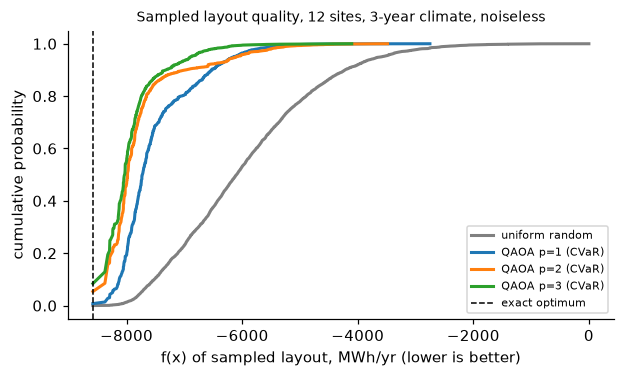

In [8]:
fig, ax = plt.subplots(figsize=(6.4, 3.4))
v_sorted = np.sort(d["values"])
ax.plot(v_sorted, np.arange(1, len(v_sorted) + 1) / len(v_sorted), color="gray", lw=2, label="uniform random")
for p, r in qaoa.items():
    states = np.array([int(s) for s in r["counts"]]); w = np.array(list(r["counts"].values()), float)
    v = d["values"][states]; o = np.argsort(v)
    ax.plot(v[o], np.cumsum(w[o]) / w.sum(), lw=2, label=f"QAOA p={p} (CVaR)")
ax.axvline(d["f_opt"], color="k", ls="--", lw=1, label="exact optimum")
ax.set_xlabel("f(x) of sampled layout, MWh/yr (lower is better)"); ax.set_ylabel("cumulative probability")
ax.set_title("Sampled layout quality, 12 sites, 3-year climate, noiseless", fontsize=9); ax.legend(fontsize=7)
fig.savefig(FIG / "distributions.png", bbox_inches="tight"); plt.show()

## 6. Noise and real hardware: IBM Quantum System One in Quebec

Each $ZZ$ term costs two-qubit gates, and IBM's heavy-hex chips connect each qubit to at most three neighbours, so dense couplings also cost SWAPs. We therefore compare the full Hamiltonian with a **sparsified** one that keeps only couplings at least 25% as strong as the strongest (sampled layouts are still scored with the *full* QUBO, so any harm from sparsifying shows up in the metrics). For each instance we run four circuits:

1. `p1_full`: depth $p=1$, every coupling
2. `p1_sparse`: $p=1$, couplings $\geq 25\%$ of the strongest
3. `p2_sparse`: $p=2$, couplings $\geq 25\%$ of the strongest
4. `control_uniform`: the same ansatz with $\gamma=\beta=0$, which should give uniformly random layouts: a noise-floor check

Hardware instances: `climate_12` (main, **3 independent runs**), `y2023_12` (the year where greedy struggles most, **3 runs**), `y2025_12` (1 run) and `climate_16` (16 qubits, 1 run, scale test). All circuits are trained in noiseless simulation (no QPU time spent on training), then executed three ways, reported in separate columns: **ideal** statevector simulation; the **IBM Heron r2 noise model** (`FakeFez`, the processor generation of today's `ibm_quebec`); and **real hardware**, `ibm_quebec` (IBM Quantum System One at PINQ² in Bromont, Quebec, the system provided for this Fall Fest), 4,000 shots per circuit with dynamical decoupling (XY4) and gate twirling.

In [9]:
from qiskit_ibm_runtime.fake_provider import FakeFez
runs = {}
for key in ["climate_12", "y2023_12", "y2025_12", "climate_16"]:
    dd = inst[key]
    # Same function the hardware run uses (`python wakewise.py hardware <instance>`), so the circuits are identical.
    circs, names, params = ww.hardware_circuits(dd["lin"], dd["W"], dd["values"], keep=0.25, alpha=ALPHA,
                                                starts=5, seed=SEED_STARTS)
    sc = lambda c, dd=dd: ww.summarize(c, dd["lin"], dd["W"], dd["f_opt"], dd["f_rand"])
    ideal = {nm: sc({s: q for s, q in enumerate(ww.ideal_probabilities(c, []))}) for nm, c in zip(names, circs)}
    model = ww.run_sampler(circs, FakeFez(), shots=SHOTS_DEVICE, seed=SEED_NOISE, names=names,
                           meta=dict(instance=key, params=params), out=ww.RESULTS / f"fake_fez_{key}.json")
    if RUN_HARDWARE:
        ww.run_sampler(circs, ww.hardware_backend(), shots=SHOTS_DEVICE, names=names,
                       meta=dict(instance=key, run=1, params=params), out=ww.RESULTS / f"hardware_{key}_r1.json")
    hw = [json.loads(open(f).read()) for f in sorted(glob.glob(str(ww.RESULTS / f"hardware_{key}_r*.json")))]
    for h in hw:
        assert all(np.allclose(h["meta"]["params"][k], v) for k, v in params.items()), f"hardware circuits differ for {key}"
    runs[key] = dict(names=names, params=params, ideal=ideal, model=model, hw=hw, score=sc, dd=dd)
    print(f"{key}: {len(dd['lin'])} qubits, {np.count_nonzero(np.triu(dd['W'], 1))} couplings "
          f"({np.count_nonzero(np.triu(ww.sparsify(dd['W'], 0.25), 1))} after sparsifying), random P(opt) {dd['p_rand']:.3%}, "
          f"{len(hw)} hardware run(s): " + ", ".join(h["job_id"] for h in hw))

first = next(r["hw"][0] for r in runs.values() if r["hw"])
print("device:", first["backend"], "| calibration snapshot at first run:", first["calibration"])
print("QPU seconds used:", sum(h["usage_s"] or 0 for r in runs.values() for h in r["hw"]))
print("Heron r2 noise model (FakeFez) calibration snapshot:", runs["climate_12"]["model"]["calibration"])

climate_12: 12 qubits, 66 couplings (32 after sparsifying), random P(opt) 0.024%, 3 hardware run(s): dbnmndgou4as73b4r6r0, dbnmnioqtr0c73adb2b0, dbnmnnc4148s73919m30


y2023_12: 12 qubits, 66 couplings (32 after sparsifying), random P(opt) 0.024%, 3 hardware run(s): dbnmo20qtr0c73adb2s0, dbnmo6c4148s73919mig, dbnmob5t7fqc73ajsu90


y2025_12: 12 qubits, 66 couplings (34 after sparsifying), random P(opt) 0.024%, 1 hardware run(s): dbnla58ou4as73b4p2p0


climate_16: 16 qubits, 120 couplings (51 after sparsifying), random P(opt) 0.002%, 1 hardware run(s): dbnmpd8ou4as73b4r920
device: ibm_quebec | calibration snapshot at first run: {'two_qubit_gate': 'cz', 'median_2q_error': 0.0015213620668354938, 'median_readout_error': 0.0078125}
QPU seconds used: 56
Heron r2 noise model (FakeFez) calibration snapshot: {'two_qubit_gate': 'cz', 'median_2q_error': 0.0039033828523107883, 'median_readout_error': 0.007568359375}


In [10]:
rows = []
for key, r in runs.items():
    dd = r["dd"]
    for k, nm in enumerate(r["names"]):
        row = {"instance": key, "circuit": nm, "2q gates": r["model"]["circuits"][k]["two_qubit_gates"],
               "ideal P(opt)": r["ideal"][nm]["p_opt"], "ideal gap": r["ideal"][nm]["gap_closed"]}
        s = r["score"](r["model"]["counts"][k])
        row.update({"noise model P(opt)": s["p_opt"], "noise model gap": s["gap_closed"]})
        if r["hw"]:
            ss = [r["score"](h["counts"][k]) for h in r["hw"]]
            po = np.array([x["p_opt"] for x in ss]); gp = np.array([x["gap_closed"] for x in ss])
            bg = np.array([beats_greedy(h["counts"][k], dd) for h in r["hw"]])
            row.update({"hardware runs": len(ss), "hardware P(opt) mean": po.mean(), "hardware P(opt) min": po.min(),
                        "hardware P(opt) max": po.max(), "hardware x random": po.mean() / dd["p_rand"],
                        "hardware gap mean": gp.mean(), "hardware gap min": gp.min(), "hardware gap max": gp.max(),
                        "hardware beats greedy": bg.mean()})
        rows.append(row)
hw_table = pd.DataFrame(rows).set_index(["instance", "circuit"])
fmt = {c: "{:.2%}" for c in hw_table.columns if "P(opt)" in c or "beats" in c} | {c: "{:.2f}" for c in hw_table.columns if "gap" in c}
fmt |= {"hardware x random": "{:,.0f}x", "hardware runs": "{:.0f}"}
hw_table.style.format(fmt, na_rep="")

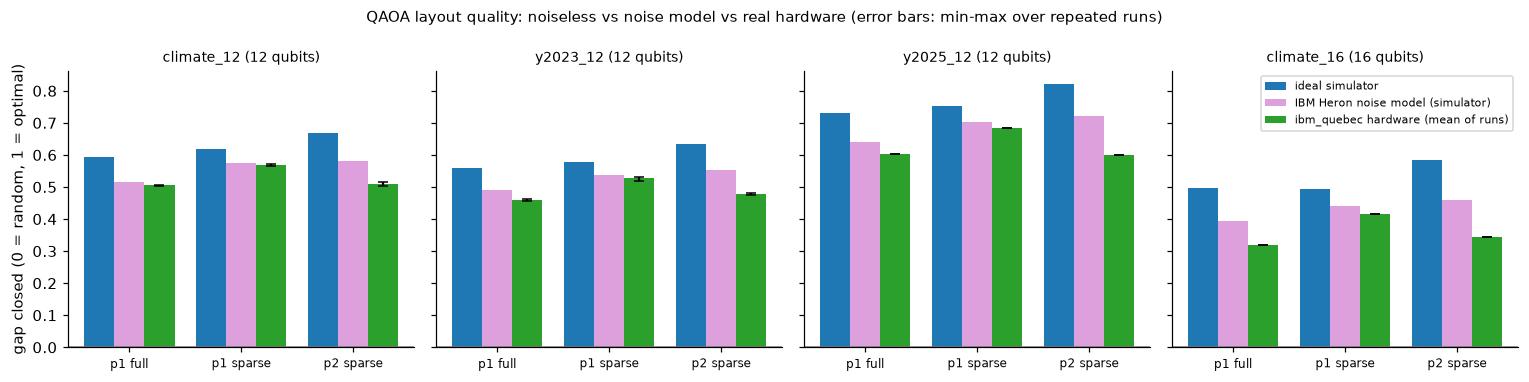

In [11]:
keys = ["climate_12", "y2023_12", "y2025_12", "climate_16"]
labels = {"ideal gap": "ideal simulator", "noise model gap": "IBM Heron noise model (simulator)", "hardware gap mean": "ibm_quebec hardware (mean of runs)"}
fig, axs = plt.subplots(1, 4, figsize=(14, 3.5), sharey=True)
for ax, key in zip(axs, keys):
    t = hw_table.loc[key].loc[runs[key]["names"][:3]]
    xs = np.arange(3); wbar = 0.27
    for j, (col, color) in enumerate([("ideal gap", "tab:blue"), ("noise model gap", "plum"), ("hardware gap mean", "tab:green")]):
        if col not in t:
            continue
        yerr = None
        if col == "hardware gap mean":
            yerr = np.vstack([t[col] - t["hardware gap min"], t["hardware gap max"] - t[col]])
        ax.bar(xs + (j - 1) * wbar, t[col], wbar, color=color, yerr=yerr, capsize=3, label=labels[col])
    ax.set_xticks(xs); ax.set_xticklabels(["p1 full", "p1 sparse", "p2 sparse"], fontsize=8)
    ax.axhline(0, color="gray", lw=1); ax.set_title(f"{key} ({len(runs[key]['dd']['lin'])} qubits)", fontsize=9)
axs[0].set_ylabel("gap closed (0 = random, 1 = optimal)")
axs[-1].legend(fontsize=7, loc="upper right")
fig.suptitle("QAOA layout quality: noiseless vs noise model vs real hardware (error bars: min-max over repeated runs)", fontsize=10)
fig.tight_layout(); fig.savefig(FIG / "noise_hardware.png", bbox_inches="tight"); plt.show()

## 7. Model check: does the pairwise QUBO rank layouts like a full wind-farm simulation?

The QUBO adds wake losses pair by pair. A full simulation lets every wake act at once (PyWake combines overlapping wakes as a root-sum-square of speed deficits). We also re-score layouts with a different, more modern wake model (Bastankhah and Porte-Agel 2014, Gaussian wakes). If the QUBO ranks layouts the same way, optimizing it is meaningful.

In [12]:
from scipy.stats import spearmanr
order = np.argsort(d["values"])
rng = np.random.default_rng(0)
check = np.unique(np.concatenate([order[:60], rng.choice(4096, 140, replace=False)]))
X = ww.bits(check, 12)
net_pair = -d["values"][check]
net_jensen = np.array([ww.layout_net(x, d["xy"], d["wd"], d["u"], d["cost"], jensen) for x in X])
net_gauss = np.array([ww.layout_net(x, d["xy"], d["wd"], d["u"], d["cost"], gaussian) for x in X])
opt_state = int(np.argmin(d["values"]))
rank = lambda net: int((net > net[check == opt_state][0]).sum()) + 1
rho_j, rho_g = spearmanr(net_pair, net_jensen)[0], spearmanr(net_pair, net_gauss)[0]
print(f"{len(check)} layouts (60 best by QUBO + 140 random)")
print(f"rank correlation with the QUBO: full-farm Jensen {rho_j:.3f}, Gaussian model {rho_g:.3f}")
print(f"the QUBO optimum ranks #{rank(net_jensen)} under full-farm Jensen and #{rank(net_gauss)} under the Gaussian model (of {len(check)})")

farm_mwh = ww.farm_energy(jensen, d["xy"][d["x_opt"] == 1], d["wd"], d["u"]).sum()
farm_loss = 1 - farm_mwh / (d["x_opt"].sum() * E)
print(f"recommended {int(d['x_opt'].sum())}-turbine layout: {farm_mwh / 1000:,.0f} GWh/yr with all wakes ({farm_loss:.1%} wake loss), "
      f"about {farm_mwh / HOME_MWH:,.0f} NL homes' electricity")

192 layouts (60 best by QUBO + 140 random)
rank correlation with the QUBO: full-farm Jensen 0.993, Gaussian model 0.992
the QUBO optimum ranks #1 under full-farm Jensen and #1 under the Gaussian model (of 192)
recommended 9-turbine layout: 154 GWh/yr with all wakes (2.5% wake loss), about 9,069 NL homes' electricity


## 8. Robustness across wind years: is the recommended layout a good decision in every year?

Wind varies from year to year. We take the optimal layout for each single year and for the 3-year climate, and score every one of them in every year. The *regret* is how much net energy a layout gives up, in a given year, compared with that year's own optimum. We also run QAOA (noiseless, $p = 3$, CVaR) on each single-year instance, where greedy falls short.

In [13]:
years = {"y2023_12": 2023, "y2024_12": 2024, "y2025_12": 2025}
designs = {"3-year climate": d["x_opt"]} | {f"{y} only": inst[k]["x_opt"] for k, y in years.items()}
regret = pd.DataFrame({f"regret in {y} (MWh/yr)": {nm: round(ww.qubo_values(x, inst[k]["lin"], inst[k]["W"])[0] - inst[k]["f_opt"])
                                                   for nm, x in designs.items()} for k, y in years.items()})
regret["mean regret (MWh/yr)"] = regret.mean(axis=1).round()
regret.insert(0, "layout", [bits(x) for x in designs.values()])
display(regret)

per_year = []
for k, y in years.items():
    dd = inst[k]
    Hy, _ = ww.qubo_to_ising(dd["lin"], dd["W"]); Hy = Hy / np.abs(Hy.coeffs).max()
    ans = ww.qaoa_circuit(Hy, 3)
    best, _ = ww.train_qaoa(ans, Hy, starts=5, seed=SEED_STARTS, values=dd["values"], alpha=ALPHA)
    pr = ww.ideal_probabilities(ans, best.x)
    per_year.append({"year": y, "greedy gap": f"{(dd['f_gr'] - dd['f_opt']) / abs(dd['f_opt']):.1%}",
                     "greedy shortfall (MWh/yr)": round(dd["f_gr"] - dd["f_opt"]),
                     "QAOA p=3 P(opt)": pr[np.isclose(dd["values"], dd["f_opt"])].sum(),
                     "x random": pr[np.isclose(dd["values"], dd["f_opt"])].sum() / dd["p_rand"],
                     "QAOA samples better than greedy": pr[dd["values"] < dd["f_gr"] - 1e-9].sum()})
per_year_table = pd.DataFrame(per_year).set_index("year")
per_year_table.style.format({"QAOA p=3 P(opt)": "{:.1%}", "x random": "{:,.0f}x", "QAOA samples better than greedy": "{:.0%}"})

,layout,regret in 2023 (MWh/yr),regret in 2024 (MWh/yr),regret in 2025 (MWh/yr),mean regret (MWh/yr)
3-year climate,111110001111,0,0,1,0.0
2023 only,111110001111,0,0,1,0.0
2024 only,111110001111,0,0,1,0.0
2025 only,111111001111,357,416,0,258.0


,greedy gap,greedy shortfall (MWh/yr),QAOA p=3 P(opt),x random,QAOA samples better than greedy
year,,,,,
2023,8.2%,704,11.9%,488x,59%
2024,5.5%,409,8.7%,357x,48%
2025,2.0%,195,9.2%,376x,13%


## 9. Results summary and what the evidence supports

In [14]:
r12, r23, r16 = runs["climate_12"], runs["y2023_12"], runs["climate_16"]
t12, t23, t16 = hw_table.loc["climate_12"], hw_table.loc["y2023_12"], hw_table.loc["climate_16"]
best12 = t12.loc[r12["names"][:3], "hardware P(opt) mean"].idxmax()
best23 = t23.loc[r23["names"][:3], "hardware P(opt) mean"].idxmax()
q3 = qaoa[3]
lines = [
    f"Real input: {len(u):,} hours of 2023-2025 Wreckhouse wind; one turbine alone yields {E:,.0f} MWh/yr; "
    f"one neighbour can cost up to {Wm.max():,.0f} MWh/yr ({Wm.max() / E:.1%}); a dense 12-turbine block loses {block_loss:.1%} to wakes.",
    f"Decision: the recommended {int(d['x_opt'].sum())}-turbine layout produces {farm_mwh / 1000:,.0f} GWh/yr (~{farm_mwh / HOME_MWH:,.0f} NL homes); "
    f"it is optimal in 2023 and 2024 and gives up {regret.loc['3-year climate', 'regret in 2025 (MWh/yr)']:.0f} MWh/yr in 2025, "
    f"while designing on 2025 alone gives up {regret.loc['2025 only', 'mean regret (MWh/yr)']:.0f} MWh/yr on average.",
    f"Classical: greedy finds the climate optimum, but falls short by 2-8% on single years (up to "
    f"{max(inst[k]['f_gr'] - inst[k]['f_opt'] for k in years):,.0f} MWh/yr).",
    "QAOA, noiseless, 12 qubits (CVaR): " + "; ".join(
        f"p={p}: P(opt) {r['p_opt']:.2%} ({r['p_opt'] / p_rand:.0f}x random)" for p, r in qaoa.items())
    + f". Shots to see the optimum with 95% confidence: {n95(q3['p_opt']):,.0f} (p=3) vs {n95(p_rand):,.0f} (random).",
    f"Single years (noiseless, p=3): " + "; ".join(f"{y}: P(opt) {row['QAOA p=3 P(opt)']:.1%}, samples better than greedy "
    f"{row['QAOA samples better than greedy']:.0%}" for y, row in per_year_table.iterrows()) + ".",
    f"Hardware, climate_12 ({len(r12['hw'])} runs): best circuit {best12}: P(opt) {t12.loc[best12, 'hardware P(opt) mean']:.2%} mean "
    f"({t12.loc[best12, 'hardware P(opt) min']:.2%}-{t12.loc[best12, 'hardware P(opt) max']:.2%}), "
    f"{t12.loc[best12, 'hardware x random']:.0f}x random; control gap closed {t12.loc['control_uniform', 'hardware gap mean']:.2f}.",
    f"Hardware, y2023_12 ({len(r23['hw'])} runs): best circuit {best23}: P(opt) {t23.loc[best23, 'hardware P(opt) mean']:.2%} "
    f"({t23.loc[best23, 'hardware x random']:.0f}x random); {t23.loc[best23, 'hardware beats greedy']:.0%} of hardware samples beat the greedy layout.",
    f"Hardware, climate_16 (scale test): gap closed {t16.loc[r16['names'][:3], 'hardware gap mean'].max():.2f} at best, "
    f"P(opt) {t16.loc[r16['names'][:3], 'hardware P(opt) mean'].max():.3%} (random {inst['climate_16']['p_rand']:.4%}).",
    f"Model check: pairwise QUBO vs full-farm Jensen rank correlation {rho_j:.3f}, vs Gaussian model {rho_g:.3f}; "
    f"QUBO optimum ranks #{rank(net_jensen)} and #{rank(net_gauss)}.",
]
print("\n".join("- " + s for s in lines))

# Single source of truth for the slides: every number quoted in the deck comes from this file.
fl = lambda v: None if v is None or (isinstance(v, float) and not np.isfinite(v)) else float(v)
summary = dict(
    hours=len(u), years=list(ww.YEARS), mean_hub_ms=fl(u.mean()), E=fl(E), capacity_factor=fl(E / (ww.RATED_KW / 1000 * 8760)),
    full_power_share=fl((p_kw >= 0.95 * ww.RATED_KW).mean()), block_loss=fl(block_loss),
    max_pair_loss=fl(Wm.max()), max_pair_loss_frac=fl(Wm.max() / E),
    spearman_jensen=fl(rho_j), spearman_gauss=fl(rho_g), rank_jensen=rank(net_jensen), rank_gauss=rank(net_gauss),
    farm_mwh=fl(farm_mwh), farm_loss=fl(farm_loss), homes=fl(farm_mwh / HOME_MWH), home_mwh=HOME_MWH,
    wind_by_year=json.loads(wind_table.reset_index().to_json(orient="records")),
    instances={k: dict(qubits=len(dd["lin"]), turbines=int(dd["x_opt"].sum()), layout=bits(dd["x_opt"]), f_opt=fl(dd["f_opt"]),
                       greedy_shortfall=fl(dd["f_gr"] - dd["f_opt"]), greedy_gap=fl((dd["f_gr"] - dd["f_opt"]) / abs(dd["f_opt"])),
                       p_rand=fl(dd["p_rand"])) for k, dd in inst.items()},
    regret=json.loads(regret.reset_index().rename(columns={"index": "design"}).to_json(orient="records")),
    per_year=json.loads(per_year_table.reset_index().to_json(orient="records")),
    sensitivity=sens,
    random=dict(p_opt=fl(p_rand), n95=fl(n95(p_rand)), within100=fl(1 - (1 - p_rand) ** 100)),
    qaoa={str(p): dict(p_opt=fl(r["p_opt"]), gap_closed=fl(r["gap_closed"]), n95=fl(n95(r["p_opt"])),
                       within100=fl(1 - (1 - r["p_opt"]) ** 100)) for p, r in qaoa.items()},
    standard={str(p): dict(p_opt=fl(r["p_opt"]), gap_closed=fl(r["gap_closed"])) for p, r in standard.items()},
    greedy_gap_closed=fl(ideal_table.loc["greedy planner (one deterministic answer)", "gap closed"]),
    devices={key: {nm: {k: fl(v) for k, v in hw_table.loc[key].loc[nm].items()} for nm in r["names"]} for key, r in runs.items()},
    hardware={key: [{k: h[k] for k in ["backend", "job_id", "utc", "shots", "usage_s", "calibration"]} for h in r["hw"]]
              for key, r in runs.items()},
    noise_model=dict(name="fake_fez", calibration=runs["climate_12"]["model"]["calibration"]),
    validation=dict(pairwise=np.round(net_pair).tolist(), full_jensen=np.round(net_jensen).tolist(), gaussian=np.round(net_gauss).tolist()),
)
(ww.RESULTS / "summary.json").write_text(json.dumps(summary, indent=1))
print("saved results/summary.json")

- Real input: 26,264 hours of 2023-2025 Wreckhouse wind; one turbine alone yields 17,575 MWh/yr; one neighbour can cost up to 425 MWh/yr (2.4%); a dense 12-turbine block loses 4.2% to wakes.
- Decision: the recommended 9-turbine layout produces 154 GWh/yr (~9,069 NL homes); it is optimal in 2023 and 2024 and gives up 1 MWh/yr in 2025, while designing on 2025 alone gives up 258 MWh/yr on average.
- Classical: greedy finds the climate optimum, but falls short by 2-8% on single years (up to 704 MWh/yr).
- QAOA, noiseless, 12 qubits (CVaR): p=1: P(opt) 0.77% (32x random); p=2: P(opt) 5.37% (220x random); p=3: P(opt) 8.42% (345x random). Shots to see the optimum with 95% confidence: 34 (p=3) vs 12,269 (random).
- Single years (noiseless, p=3): 2023: P(opt) 11.9%, samples better than greedy 59%; 2024: P(opt) 8.7%, samples better than greedy 48%; 2025: P(opt) 9.2%, samples better than greedy 13%.
- Hardware, climate_12 (3 runs): best circuit p1_full: P(opt) 0.53% mean (0.47%-0.60%), 22x rando

**What the evidence supports**

* The siting problem is combinatorial on real NL wind, and the pairwise QUBO matches full PyWake simulations, so optimizing it is meaningful.
* The recommended (3-year climate) layout is robust across real wind years; designing on a single year is not (the 2025-only design gives up 258 MWh/yr on average).
* QAOA in Qiskit concentrates probability on the best layout (hundreds of times above random guessing in noiseless simulation), improves with depth, and benefits from CVaR training; on single years, where greedy falls short, many of its samples beat greedy.
* The signal survives real IBM hardware and is repeatable across runs: about 22 times random on the 3-year instance, and about 1 in 6 samples beating greedy on 2023's wind (random: 1 in 50). The noise model predicts the hardware behaviour well.
* What it does **not** support: any quantum advantage (a laptop enumerates every layout, and greedy already finds the long-term optimum); real-world energy figures (idealized parcel, illustrative costs); scaling on today's hardware (at 16 qubits the optimum was not sampled).

## 10. Limitations, assumptions, resources and next steps

* **Model:** flat terrain, three wind years, 10 m data extrapolated to hub height, a generic 4 MW turbine, and costs expressed as energy are simplifications. PyWake models are engineering models, not field measurements.
* **Quantum:** QAOA depth $p \le 3$, trained in noiseless simulation; dense couplings need many SWAPs on heavy-hex connectivity, which is why hardware circuits use depth 1 to 2 and why we sparsify. At 16 qubits the optimum itself is rarely sampled on hardware: the method's reach on today's devices ends around here.
* **Resources:** each noiseless experiment takes seconds to minutes on a laptop; the full notebook about 15 minutes. Hardware: 4 circuits x 4,000 shots per job on `ibm_quebec`; QPU seconds and job IDs are recorded in `results/hardware_*.json`.
* **Next steps:** a real Codroy Valley parcel with terrain-aware wind; spacing and exclusion constraints (wetlands, caribou habitat) as extra QUBO terms; constraint-preserving mixers and warm starts; larger instances where exact enumeration is impossible and QAOA must be compared with strong classical heuristics (simulated annealing, MILP). A natural home is MUN's CREATE-SWIFT program, with Mitacs Accelerate as a route to an industry partner.

## 11. Credits and team contribution

* **Reused and adapted:** the QAOA workflow pattern (QUBO -> Ising -> ansatz -> optimizer -> Sampler) from Tinh Bui's *Quantum Optimization* workshop notebook (Qiskit Fall Fest 2026), whose brute-force answer selection we deliberately replace with selection from samples; IBM runtime setup and Sampler options from the *Qiskit 101* hands-on notebook (IBM, Apache 2.0) and the Fall Fest IBM hardware example (credential names `apikey` and `crn`, channel `ibm_quantum_platform`); Qiskit, Qiskit Aer, Qiskit IBM Runtime (Apache 2.0); DTU PyWake (MIT licence; Pedersen et al., DTU Wind Energy); NumPy, SciPy, pandas, Matplotlib.
* **Data:** Environment and Climate Change Canada hourly climate data (Open Government Licence, Canada); NL household electricity use from the NL Government (2026 release on the electricity rebate: about 1,400 to 1,500 kWh per month).
* **Methods from the literature:** Jensen (1983) and Katic, Højstrup and Jensen (1986) wake model; Bastankhah and Porte-Agel (2014) Gaussian wake model; Mosetti, Poloni and Diviacco (1994) grid-based layout optimization; Farhi, Goldstone and Gutmann (2014) QAOA; Barkoutsos et al. (2020) CVaR objective; prior QUBO formulations of wind-farm layout (e.g., Senderovich et al., 2022).
* **Our contribution:** the problem framing for NL's west coast, the QUBO built from three years of real Wreckhouse wind and PyWake pair simulations, the validation design (exact, greedy and random baselines on the same instances, full-farm and Gaussian model checks, year-to-year robustness, sparsification study, noise model, repeated hardware runs, control circuits, 16-qubit scale test), all code in `wakewise.py`, the tests, and the experiments and their interpretation. AI tools (Claude) assisted with code and writing; the team reviewed and can explain every part.